#### Importing the required libraries

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Configuring display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

# Defining project directories

processed_dir = Path("../data/processed")
preprocessed_models_dir = Path("../models/preprocessed")
trained_models_dir = Path("../models/trained")
figures_dir = Path("../reports/figures")

figures_dir.mkdir(parents=True, exist_ok=True)

# Configuring reproducibility

RANDOM_STATE = 42

print("Libraries Imported Successfully.")
print("Explainability Directories Configured Successfully.")

Libraries Imported Successfully.
Explainability Directories Configured Successfully.


#### 1. Loading Data and Trained Models

In [2]:
# Loading processed training and test features

X_train = pd.read_parquet(
    processed_dir / "X_train_processed.parquet"
)

X_test = pd.read_parquet(
    processed_dir / "X_test_processed.parquet"
)

# Loading encoded target variables

y_train = pd.read_parquet(
    processed_dir / "y_train_encoded.parquet"
).to_numpy().ravel()

y_test = pd.read_parquet(
    processed_dir / "y_test_encoded.parquet"
).to_numpy().ravel()

# Loading feature names and label encoder

feature_names = joblib.load(
    preprocessed_models_dir / "feature_names.joblib"
)

label_encoder = joblib.load(
    preprocessed_models_dir / "label_encoder.joblib"
)

# Loading trained models

tuned_svm = joblib.load(
    trained_models_dir / "tuned_svm.joblib"
)

tuned_knn = joblib.load(
    trained_models_dir / "tuned_knn.joblib"
)

random_forest = joblib.load(
    trained_models_dir / "random_forest.joblib"
)

# Verifying loaded datasets and models

print("Training Features:", X_train.shape)
print("Test Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Test Target:", y_test.shape)

print("\nTotal Features:", len(feature_names))
print("Severity Classes:", label_encoder.classes_)

print("\nLoaded Models:")
print("- Tuned SVM")
print("- Tuned KNN")
print("- Random Forest")

print("\nFeature Names:")
display(pd.DataFrame({"Feature": feature_names}))

Training Features: (800, 13)
Test Features: (200, 13)

Training Target: (800,)
Test Target: (200,)

Total Features: 13
Severity Classes: ['Critical' 'Minor' 'Moderate']

Loaded Models:
- Tuned SVM
- Tuned KNN
- Random Forest

Feature Names:


,Feature
0,categorical__defect_type_Cosmetic
1,categorical__defect_type_Functional
2,categorical__defect_type_Structural
3,categorical__defect_location_Component
4,categorical__defect_location_Internal
5,categorical__defect_location_Surface
6,categorical__inspection_method_Automated Testing
7,categorical__inspection_method_Manual Testing
8,categorical__inspection_method_Visual Inspection
9,numerical__Month


#### Observations on Processed Features

- The processed dataset contains **13 features**, including 9 one-hot encoded categorical variables, 3 scaled numerical variables, and 1 binary variable.
- Defect type, defect location, and inspection method are represented through categorical indicators.
- Temporal features capture the month, day, weekday, and weekend status of defect records.

#### 2. Investigating Tuned SVM Coefficients

In [3]:
# Inspecting the linear SVM coefficients

svm_coefficients = tuned_svm.coef_

# Identifying pairwise severity comparisons

class_names = label_encoder.classes_

class_pairs = [
    (class_names[i], class_names[j])
    for i in range(len(class_names))
    for j in range(i + 1, len(class_names))
]

# Organizing coefficients by class comparison

svm_coefficient_df = pd.DataFrame(
    svm_coefficients,
    columns=feature_names,
    index=[
        f"{class_a} vs {class_b}"
        for class_a, class_b in class_pairs
    ]
)

print("SVM Coefficient Matrix Shape:", svm_coefficients.shape)

print("\nPairwise Severity Coefficients:")
display(svm_coefficient_df.T.round(4))

SVM Coefficient Matrix Shape: (3, 13)

Pairwise Severity Coefficients:


,Critical vs Minor,Critical vs Moderate,Minor vs Moderate
categorical__defect_type_Cosmetic,0.1625,0.0022,0.0020
categorical__defect_type_Functional,-0.1181,-0.0171,-0.3421
categorical__defect_type_Structural,-0.0444,0.0149,0.3400
categorical__defect_location_Component,0.0171,-0.0015,0.0943
categorical__defect_location_Internal,-0.1313,0.0104,0.1351
categorical__defect_location_Surface,0.1143,-0.0089,-0.2294
categorical__inspection_method_Automated Testing,0.0647,-0.0041,-0.1299
categorical__inspection_method_Manual Testing,-0.1181,0.0168,0.3631
categorical__inspection_method_Visual Inspection,0.0534,-0.0128,-0.2332
numerical__Month,-0.2916,0.0035,0.1825


#### Observations on Tuned SVM Coefficients

- **Is_Weekend** recorded the largest absolute coefficients across all three pairwise severity comparisons, particularly Critical vs Moderate (**−1.9140**).
- **Day** and **Month** showed notable coefficients in the Critical vs Minor comparison, while defect type and inspection method contributed to Minor vs Moderate separation.
- Coefficient patterns varied across severity comparisons, indicating different learned decision boundaries rather than a consistent predictor of defect severity.

##### 2.1 Visualizing Pairwise Feature Coefficients

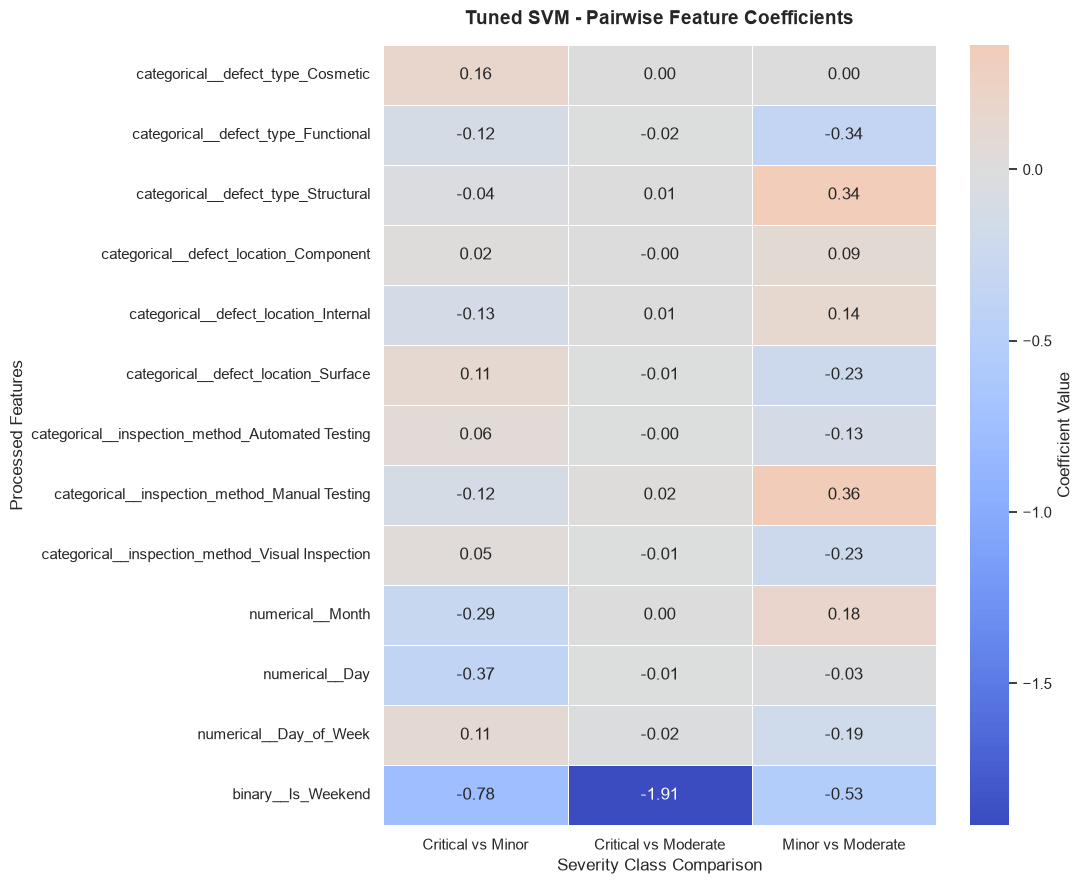

In [4]:
# Visualizing pairwise SVM feature coefficients

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    svm_coefficient_df.T,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Coefficient Value"},
    ax=ax
)

ax.set_title(
    "Tuned SVM - Pairwise Feature Coefficients",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Severity Class Comparison")
ax.set_ylabel("Processed Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "tuned_svm_coefficient_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### 3. Investigating Permutation Feature Importance

In [5]:
# Calculating permutation importance for Tuned SVM

permutation_results = permutation_importance(
    estimator=tuned_svm,
    X=X_train,
    y=y_train,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

# Organizing permutation importance results

permutation_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

permutation_importance_df = (
    permutation_importance_df
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

print("Tuned SVM - Permutation Feature Importance:")

display(permutation_importance_df.round(4))

Tuned SVM - Permutation Feature Importance:


,Feature,Importance_Mean,Importance_Std
0,binary__Is_Weekend,0.0456,0.0081
1,categorical__defect_type_Cosmetic,0.0031,0.0022
2,categorical__inspection_method_Automated Testing,0.0012,0.0049
3,categorical__inspection_method_Manual Testing,0.0011,0.0045
4,numerical__Day_of_Week,0.0007,0.0050
5,categorical__defect_type_Functional,-0.0010,0.0053
6,numerical__Day,-0.0013,0.0092
7,numerical__Month,-0.0027,0.0083
8,categorical__defect_type_Structural,-0.0028,0.0045
9,categorical__defect_location_Component,-0.0040,0.0013


#### Observations on Permutation Feature Importance

- **Is_Weekend** recorded the highest permutation importance (**0.0456**), indicating the strongest influence on the model's training Macro F1-score.
- **Defect type** and **inspection method** features showed minimal positive importance, suggesting limited contributions to model performance.
- Several defect location and temporal features recorded negative importance, indicating that shuffling them slightly improved training performance.

##### 3.1 Visualizing Permutation Feature Importance

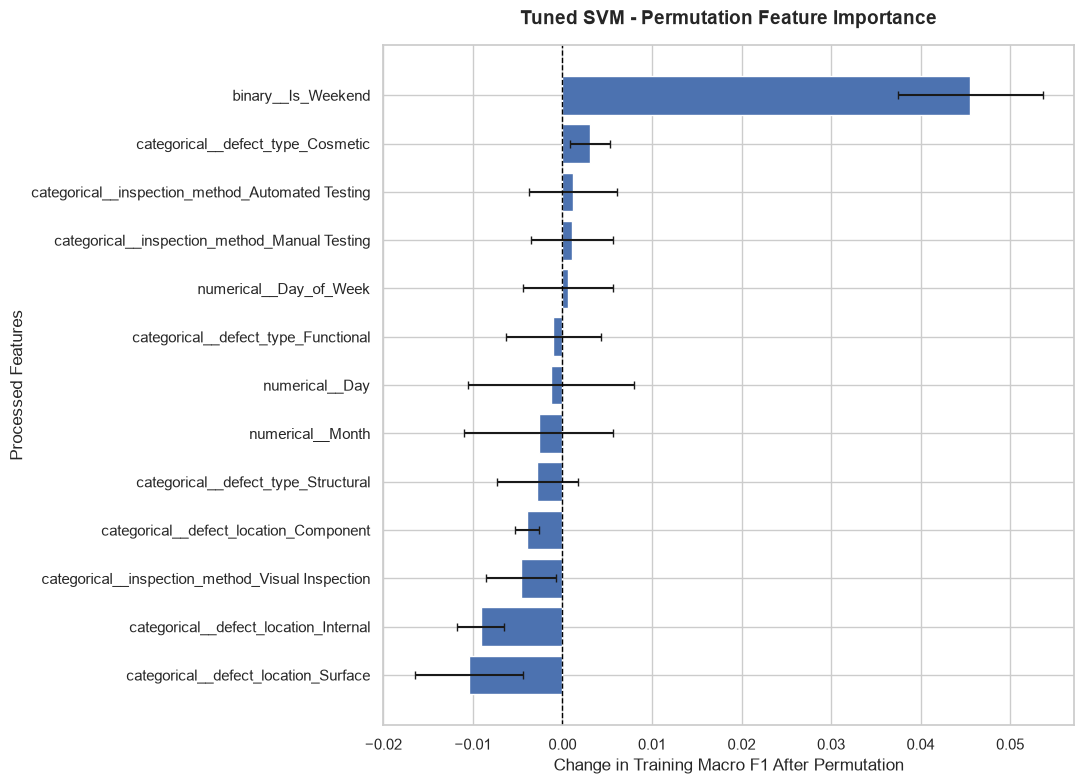

In [6]:
# Visualizing Tuned SVM permutation feature importance

plot_data = permutation_importance_df.sort_values(
    "Importance_Mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    plot_data["Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_Std"],
    capsize=3
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Tuned SVM - Permutation Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Change in Training Macro F1 After Permutation")
ax.set_ylabel("Processed Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "tuned_svm_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 4. Investigating Original Feature Importance

In [7]:
# Grouping processed features by their original variables

feature_groups = {
    "Defect Type": [
        col for col in X_train.columns
        if col.startswith("categorical__defect_type_")
    ],
    "Defect Location": [
        col for col in X_train.columns
        if col.startswith("categorical__defect_location_")
    ],
    "Inspection Method": [
        col for col in X_train.columns
        if col.startswith("categorical__inspection_method_")
    ],
    "Month": ["numerical__Month"],
    "Day": ["numerical__Day"],
    "Day of Week": ["numerical__Day_of_Week"],
    "Is Weekend": ["binary__Is_Weekend"]
}

# Verifying feature group coverage

grouped_columns = [
    col
    for columns in feature_groups.values()
    for col in columns
]

assert len(grouped_columns) == len(set(grouped_columns)), (
    "Some processed features appear in multiple groups."
)

assert set(grouped_columns) == set(X_train.columns), (
    "Feature groups do not match the processed dataset."
)

# Calculating baseline training Macro F1

baseline_f1 = f1_score(
    y_train,
    tuned_svm.predict(X_train),
    average="macro"
)

# Calculating grouped permutation importance

rng = np.random.default_rng(RANDOM_STATE)

group_importance_results = []

for group_name, columns in feature_groups.items():

    importance_scores = []

    for repeat in range(10):

        X_permuted = X_train.copy()

        # Shuffling all columns in a group using the same row permutation

        shuffled_indices = rng.permutation(len(X_train))

        X_permuted.loc[:, columns] = (
            X_train[columns].iloc[shuffled_indices].to_numpy()
        )

        permuted_f1 = f1_score(
            y_train,
            tuned_svm.predict(X_permuted),
            average="macro"
        )

        importance_scores.append(baseline_f1 - permuted_f1)

    group_importance_results.append({
        "Original_Feature": group_name,
        "Importance_Mean": np.mean(importance_scores),
        "Importance_Std": np.std(importance_scores),
        "Processed_Features": len(columns)
    })

# Organizing results

original_feature_importance = (
    pd.DataFrame(group_importance_results)
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

print("Baseline Training Macro F1:", round(baseline_f1, 4))

print("\nTuned SVM - Original Feature Importance:")

display(original_feature_importance.round(4))

Baseline Training Macro F1: 0.3931

Tuned SVM - Original Feature Importance:


,Original_Feature,Importance_Mean,Importance_Std,Processed_Features
0,Is Weekend,0.0448,0.0112,1
1,Inspection Method,0.0069,0.0069,3
2,Defect Type,0.0044,0.0057,3
3,Day,-0.0010,0.0068,1
4,Day of Week,-0.0014,0.0080,1
5,Month,-0.0017,0.0099,1
6,Defect Location,-0.0097,0.0073,3


#### Observations on Original Feature Importance

- **Is Weekend** recorded the highest permutation importance (**0.0448**), indicating the strongest contribution to the model's training Macro F1-score.
- **Inspection Method (0.0069)** and **Defect Type (0.0044)** showed limited positive importance, suggesting relatively weak predictive contributions.
- **Defect Location** recorded negative importance (**−0.0097**), while the remaining temporal features contributed little to training performance.

##### 4.1 Visualizing Original Feature Importance

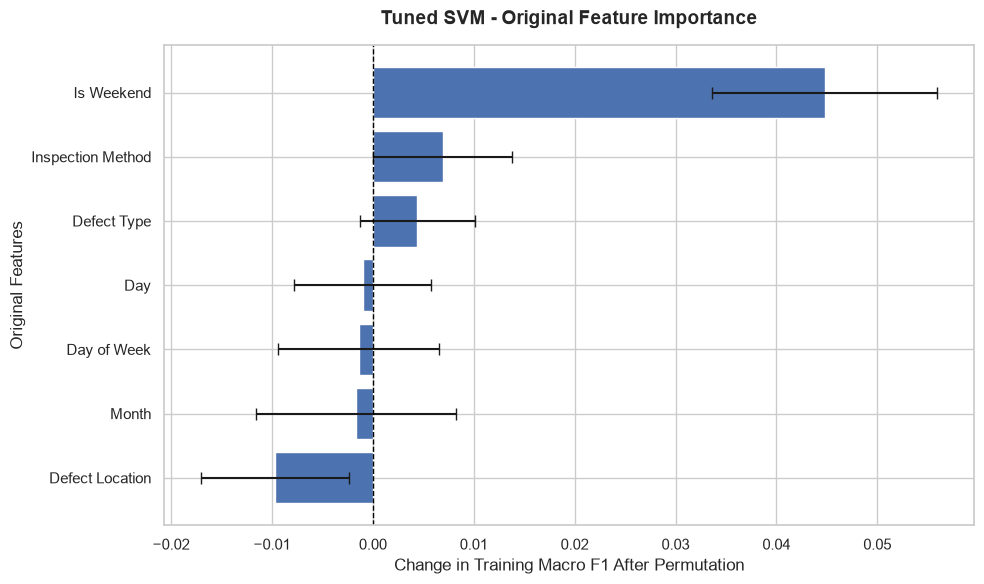

In [8]:
# Visualizing original feature permutation importance

plot_data = original_feature_importance.sort_values(
    "Importance_Mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["Original_Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_Std"],
    capsize=4
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Tuned SVM - Original Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Change in Training Macro F1 After Permutation")
ax.set_ylabel("Original Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "original_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 5. Investigating Tree-Based Feature Importance

In [9]:
# Extracting Random Forest feature importance

rf_importance = random_forest.feature_importances_

# Organizing feature importance results

rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

rf_importance_df = (
    rf_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Verifying feature importance

print("Random Forest - Feature Importance:")
display(rf_importance_df.round(4))

print("\nTotal Feature Importance:", round(rf_importance.sum(), 4))

Random Forest - Feature Importance:


,Feature,Importance
0,numerical__Day,0.3419
1,numerical__Month,0.1928
2,numerical__Day_of_Week,0.1606
3,categorical__defect_location_Surface,0.0339
4,categorical__defect_type_Cosmetic,0.0334
5,categorical__defect_location_Internal,0.0326
6,categorical__defect_type_Structural,0.0321
7,categorical__defect_location_Component,0.0321
8,categorical__defect_type_Functional,0.0318
9,categorical__inspection_method_Visual Inspection,0.0302



Total Feature Importance: 1.0


#### Observations on Random Forest Feature Importance

- **Day (34.19%)** recorded the highest importance, followed by **Month (19.28%)** and **Day of Week (16.06%)**.
- Temporal features collectively accounted for approximately **71.48%** of total feature importance, indicating substantial reliance on date-related variables.
- **Is Weekend (1.95%)** showed the lowest importance, contrasting with its dominant role in the Tuned SVM permutation analysis.

##### 5.1 Visualizing Random Forest Feature Importance

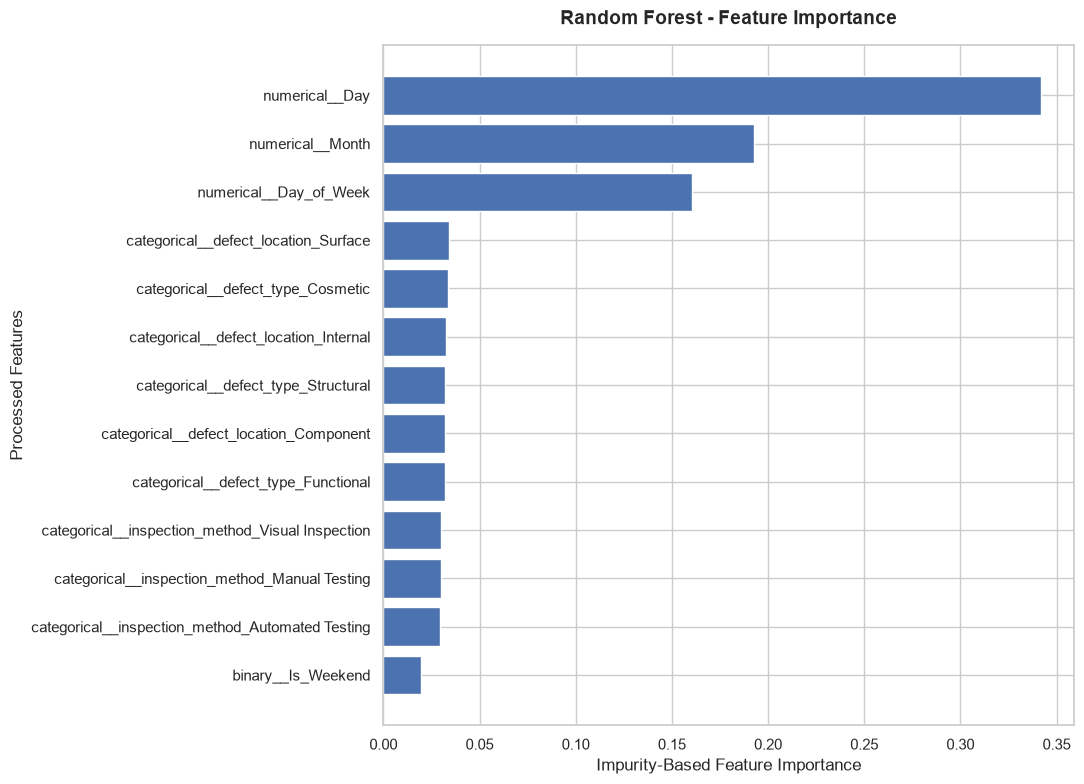

In [10]:
# Visualizing Random Forest feature importance

plot_data = rf_importance_df.sort_values(
    "Importance",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    plot_data["Feature"],
    plot_data["Importance"]
)

ax.set_title(
    "Random Forest - Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Impurity-Based Feature Importance")
ax.set_ylabel("Processed Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### 5.2 Investigating Random Forest Permutation Importance

In [11]:
# Calculating Random Forest permutation importance

rf_permutation_results = permutation_importance(
    estimator=random_forest,
    X=X_train,
    y=y_train,
    scoring="f1_macro",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Organizing permutation importance results

rf_permutation_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance_Mean": rf_permutation_results.importances_mean,
    "Importance_Std": rf_permutation_results.importances_std
})

rf_permutation_df = (
    rf_permutation_df
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

# Displaying results

print("Random Forest - Permutation Feature Importance:")

display(rf_permutation_df.round(4))

Random Forest - Permutation Feature Importance:


,Feature,Importance_Mean,Importance_Std
0,numerical__Day,0.2883,0.0158
1,numerical__Month,0.2454,0.0113
2,numerical__Day_of_Week,0.1966,0.0072
3,binary__Is_Weekend,0.0654,0.0112
4,categorical__inspection_method_Manual Testing,0.0653,0.0057
5,categorical__defect_location_Surface,0.0544,0.0058
6,categorical__defect_type_Structural,0.0487,0.0042
7,categorical__defect_type_Functional,0.0387,0.0046
8,categorical__defect_location_Internal,0.0334,0.0032
9,categorical__inspection_method_Visual Inspection,0.0333,0.0046


#### Observations on Random Forest Permutation Importance

- **Day (0.2883)** recorded the highest permutation importance, followed by **Month (0.2454)** and **Day of Week (0.1966)**, confirming the model's strong reliance on temporal features.
- **Is Weekend (0.0654)** and **Manual Testing (0.0653)** showed moderate importance, while defect type and location features contributed comparatively less.
- All 13 processed features recorded positive importance, indicating that shuffling each feature reduced the model's training Macro F1-score.

##### 5.3 Visualizing Random Forest Permutation Importance

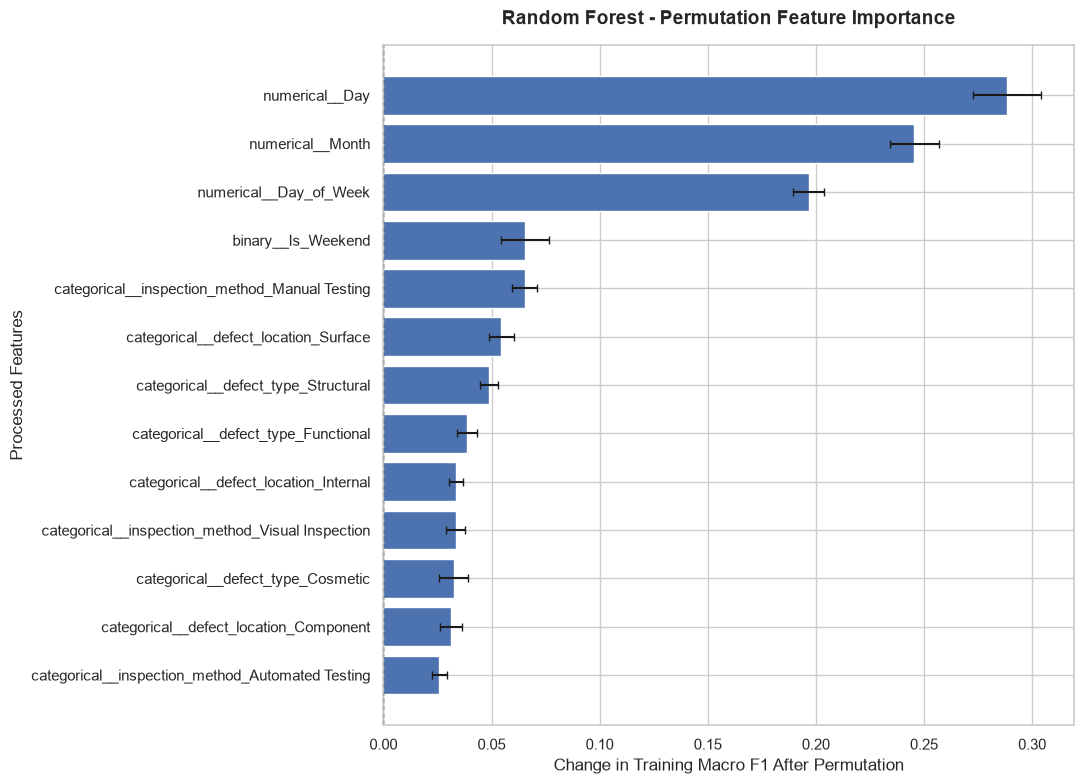

In [12]:
# Visualizing Random Forest permutation importance

plot_data = rf_permutation_df.sort_values(
    "Importance_Mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    plot_data["Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_Std"],
    capsize=3
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Random Forest - Permutation Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Change in Training Macro F1 After Permutation")
ax.set_ylabel("Processed Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "random_forest_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 5.4 Investigating Original Feature Importance

In [13]:
# Calculating grouped permutation importance for Random Forest

rf_baseline_f1 = f1_score(
    y_train,
    random_forest.predict(X_train),
    average="macro"
)

rng = np.random.default_rng(RANDOM_STATE)

rf_group_importance_results = []

for group_name, columns in feature_groups.items():

    importance_scores = []

    for repeat in range(10):

        X_permuted = X_train.copy()

        # Shuffling grouped features using a shared row permutation

        shuffled_indices = rng.permutation(len(X_train))

        X_permuted.loc[:, columns] = (
            X_train[columns].iloc[shuffled_indices].to_numpy()
        )

        permuted_f1 = f1_score(
            y_train,
            random_forest.predict(X_permuted),
            average="macro"
        )

        importance_scores.append(
            rf_baseline_f1 - permuted_f1
        )

    rf_group_importance_results.append({
        "Original_Feature": group_name,
        "Importance_Mean": np.mean(importance_scores),
        "Importance_Std": np.std(importance_scores),
        "Processed_Features": len(columns)
    })

# Organizing results

rf_original_feature_importance = (
    pd.DataFrame(rf_group_importance_results)
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

print("Random Forest - Baseline Training Macro F1:")
print(round(rf_baseline_f1, 4))

print("\nRandom Forest - Original Feature Importance:")
display(rf_original_feature_importance.round(4))

Random Forest - Baseline Training Macro F1:
0.9365

Random Forest - Original Feature Importance:


,Original_Feature,Importance_Mean,Importance_Std,Processed_Features
0,Defect Location,0.3428,0.0131,3
1,Inspection Method,0.3325,0.0191,3
2,Defect Type,0.3235,0.0080,3
3,Day,0.2846,0.0110,1
4,Month,0.2508,0.0122,1
5,Day of Week,0.2007,0.0062,1
6,Is Weekend,0.0723,0.0065,1


#### Observations on Original Feature Importance

- **Defect Location (0.3428)** recorded the highest grouped permutation importance, followed closely by **Inspection Method (0.3325)** and **Defect Type (0.3235)**.
- **Day (0.2846)** and **Month (0.2508)** also contributed substantially, while **Is Weekend (0.0723)** showed the lowest grouped importance.
- The model achieved a **training Macro F1-score of 0.9365**, substantially exceeding its test Macro F1-score of 0.3236, indicating severe overfitting.

##### 5.5 Visualizing Original Feature Importance

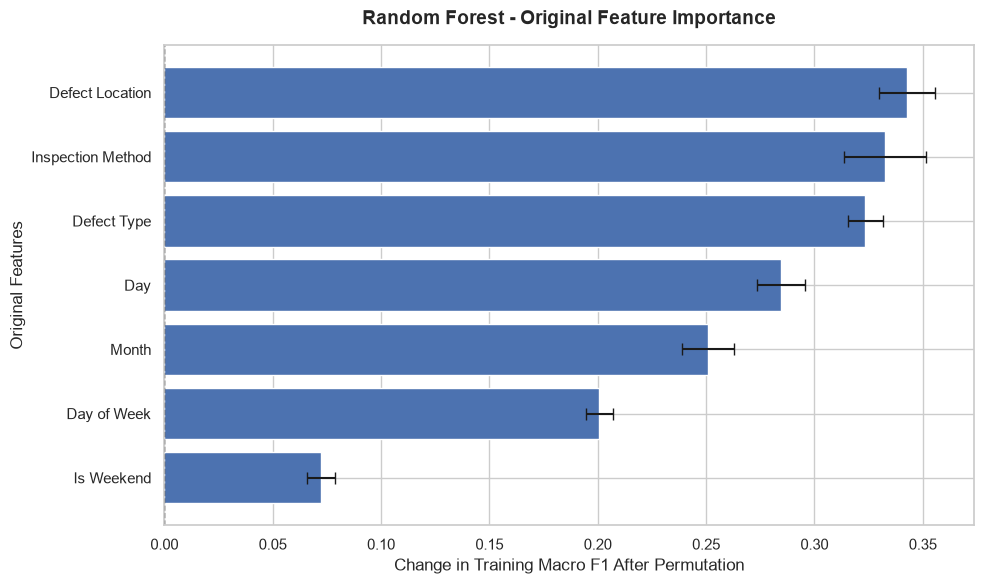

In [14]:
# Visualizing Random Forest original feature importance

plot_data = rf_original_feature_importance.sort_values(
    "Importance_Mean",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data["Original_Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_Std"],
    capsize=4
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Random Forest - Original Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Change in Training Macro F1 After Permutation")
ax.set_ylabel("Original Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "random_forest_original_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 6. Comparing Feature Importance Across Models

In [15]:
# Preparing Tuned SVM feature importance rankings

svm_ranking = original_feature_importance[
    ["Original_Feature", "Importance_Mean"]
].copy()

svm_ranking = svm_ranking.rename(
    columns={"Importance_Mean": "SVM_Importance"}
)

svm_ranking["SVM_Rank"] = (
    svm_ranking["SVM_Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Preparing Random Forest feature importance rankings

rf_ranking = rf_original_feature_importance[
    ["Original_Feature", "Importance_Mean"]
].copy()

rf_ranking = rf_ranking.rename(
    columns={"Importance_Mean": "RF_Importance"}
)

rf_ranking["RF_Rank"] = (
    rf_ranking["RF_Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Combining model rankings

feature_ranking_comparison = pd.merge(
    svm_ranking,
    rf_ranking,
    on="Original_Feature",
    how="inner",
    validate="one_to_one"
)

feature_ranking_comparison["Rank_Difference"] = (
    feature_ranking_comparison["SVM_Rank"]
    - feature_ranking_comparison["RF_Rank"]
).abs()

feature_ranking_comparison = (
    feature_ranking_comparison
    .sort_values("SVM_Rank")
    .reset_index(drop=True)
)

print("Cross-Model Feature Importance Comparison:")

display(feature_ranking_comparison.round(4))

Cross-Model Feature Importance Comparison:


,Original_Feature,SVM_Importance,SVM_Rank,RF_Importance,RF_Rank,Rank_Difference
0,Is Weekend,0.0448,1,0.0723,7,6
1,Inspection Method,0.0069,2,0.3325,2,0
2,Defect Type,0.0044,3,0.3235,3,0
3,Day,-0.0010,4,0.2846,4,0
4,Day of Week,-0.0014,5,0.2007,6,1
5,Month,-0.0017,6,0.2508,5,1
6,Defect Location,-0.0097,7,0.3428,1,6


#### Observations on Cross-Model Feature Importance

- **Is Weekend** ranked first for Tuned SVM but seventh for Random Forest, showing a substantial difference in feature reliance.
- **Defect Location** ranked seventh for Tuned SVM but first for Random Forest, representing the largest contrasting importance pattern.
- **Inspection Method** and **Defect Type** maintained identical rankings across both models, ranking second and third, respectively, although their importance magnitudes differed considerably.

##### 6.1 Visualizing Cross-Model Feature Rankings

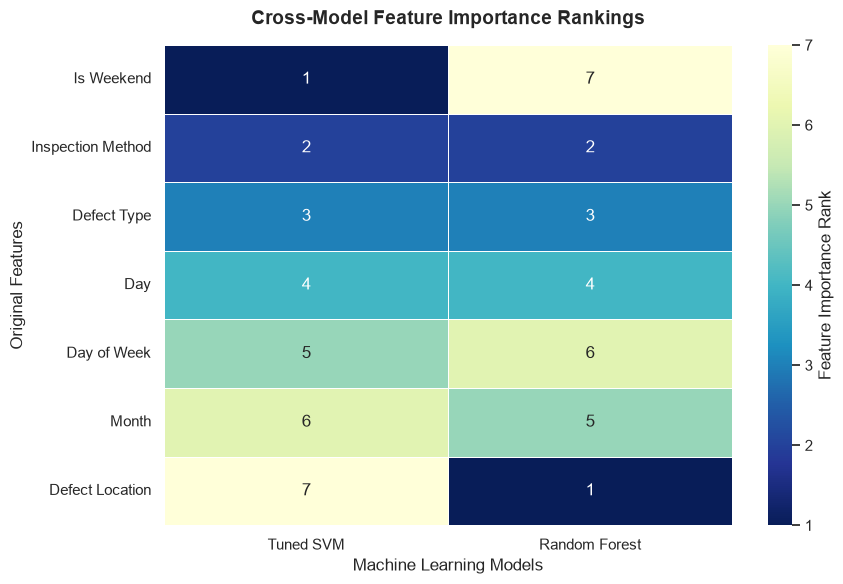

In [16]:
# Preparing cross-model feature ranking heatmap

ranking_heatmap = (
    feature_ranking_comparison
    .set_index("Original_Feature")[
        ["SVM_Rank", "RF_Rank"]
    ]
    .rename(columns={
        "SVM_Rank": "Tuned SVM",
        "RF_Rank": "Random Forest"
    })
)

# Visualizing feature importance rankings

fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    ranking_heatmap,
    annot=True,
    fmt="d",
    cmap="YlGnBu_r",
    linewidths=0.5,
    vmin=1,
    vmax=7,
    cbar_kws={"label": "Feature Importance Rank"},
    ax=ax
)

ax.set_title(
    "Cross-Model Feature Importance Rankings",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Original Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "cross_model_feature_importance_rankings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### 7. Saving Explainability Results

In [17]:
# Saving Tuned SVM explainability results

svm_coefficient_df.to_csv(
    processed_dir / "tuned_svm_coefficients.csv"
)

permutation_importance_df.to_csv(
    processed_dir / "tuned_svm_permutation_importance.csv",
    index=False
)

original_feature_importance.to_csv(
    processed_dir / "tuned_svm_original_feature_importance.csv",
    index=False
)

# Saving Random Forest explainability results

rf_importance_df.to_csv(
    processed_dir / "random_forest_impurity_importance.csv",
    index=False
)

rf_permutation_df.to_csv(
    processed_dir / "random_forest_permutation_importance.csv",
    index=False
)

rf_original_feature_importance.to_csv(
    processed_dir / "random_forest_original_feature_importance.csv",
    index=False
)

# Saving cross-model comparison

feature_ranking_comparison.to_csv(
    processed_dir / "cross_model_feature_importance_comparison.csv",
    index=False
)

# Verifying saved files

explainability_files = [
    "tuned_svm_coefficients.csv",
    "tuned_svm_permutation_importance.csv",
    "tuned_svm_original_feature_importance.csv",
    "random_forest_impurity_importance.csv",
    "random_forest_permutation_importance.csv",
    "random_forest_original_feature_importance.csv",
    "cross_model_feature_importance_comparison.csv"
]

for filename in explainability_files:
    filepath = processed_dir / filename
    print(f"{filename}: {'Saved' if filepath.exists() else 'Missing'}")

tuned_svm_coefficients.csv: Saved
tuned_svm_permutation_importance.csv: Saved
tuned_svm_original_feature_importance.csv: Saved
random_forest_impurity_importance.csv: Saved
random_forest_permutation_importance.csv: Saved
random_forest_original_feature_importance.csv: Saved
cross_model_feature_importance_comparison.csv: Saved


## 8. Key Findings and Limitations

### 8.1 Key Findings

1. **Tuned SVM Feature Importance:** Weekend status showed the strongest positive permutation importance, while defect type, location, and inspection method contributed relatively little to the model's training Macro F1-score.

2. **Random Forest Feature Importance:** Random Forest assigned substantial importance to temporal features using both impurity-based and permutation-based methods. Grouped permutation analysis also revealed strong reliance on defect location, inspection method, and defect type.

3. **Cross-Model Differences:** The two models identified different dominant features. Weekend status ranked highest for Tuned SVM, whereas defect location ranked highest for Random Forest.

4. **Model Generalization:** Random Forest achieved a training Macro F1-score of 0.9365 but only 0.3236 on the test dataset, indicating substantial overfitting. Tuned SVM also showed limited generalization, with its cross-validation Macro F1-score of 0.3710 declining to 0.2679 on the test dataset.

### 8.2 Limitations

- **Limited Predictive Signal:** The models demonstrated weak performance on unseen observations, restricting the reliability of their feature importance interpretations.
- **Training-Based Explanations:** Permutation importance was calculated using training data and therefore describes fitted model behavior rather than independently validated predictive relationships.
- **Synthetic Dataset:** The dataset may not adequately represent real-world manufacturing processes or the factors governing defect severity.
- **Feature Dependencies:** Relationships among temporal features, particularly Day of Week and Is Weekend, may affect individual importance estimates.
- **Non-Causal Interpretations:** Feature importance indicates model reliance and does not establish causal relationships with defect severity.

## 9. Conclusion

The model explainability analysis examined how manufacturing defect characteristics, inspection methods, and temporal features influenced predictions across Tuned SVM and Random Forest classifiers.

The findings revealed considerable differences in feature reliance between the two models. Tuned SVM emphasized weekend status, while Random Forest relied more broadly on temporal variables and manufacturing defect characteristics.

However, weak generalization performance, substantial Random Forest overfitting, and inconsistencies across model explanations limit the reliability of these patterns.

Overall, the analysis provides insight into how the trained classifiers make predictions, while highlighting the need for more informative data and stronger generalization before these findings can support operational quality assurance decisions.

#### 10. Investigating SHAP-Based Model Explainability

SHAP (SHapley Additive exPlanations) is used to interpret how individual features contribute to machine learning predictions.

This analysis applies SHAP to the trained Random Forest classifier to investigate feature contributions across the three manufacturing defect severity classes: Critical, Minor, and Moderate.

The analysis includes global feature importance and individual prediction explanations. Given the model's limited generalization performance, SHAP values are interpreted as explanations of model behavior rather than evidence of reliable or causal relationships.

In [18]:
# Importing and verifying SHAP

import shap

print("SHAP Version:", shap.__version__)

print("\nRandom Forest Model:")
print(type(random_forest).__name__)

print("\nTraining Dataset Shape:", X_train.shape)
print("Testing Dataset Shape:", X_test.shape)

print("\nDefect Severity Classes:")
print(label_encoder.classes_)

SHAP Version: 0.51.0

Random Forest Model:
RandomForestClassifier

Training Dataset Shape: (800, 13)
Testing Dataset Shape: (200, 13)

Defect Severity Classes:
['Critical' 'Minor' 'Moderate']


##### 10.1 Initializing the SHAP Explainer

In [19]:
# Preparing a representative sample for SHAP analysis

X_shap = X_train.sample(
    n=100,
    random_state=RANDOM_STATE
)

# Initializing SHAP TreeExplainer

shap_explainer = shap.TreeExplainer(random_forest)

# Calculating SHAP values

shap_values = shap_explainer(X_shap)

# Verifying SHAP output dimensions

print("SHAP Sample Shape:", X_shap.shape)
print("SHAP Values Shape:", shap_values.values.shape)
print("Base Values Shape:", shap_values.base_values.shape)

print("\nSeverity Classes:")
print(label_encoder.classes_)

SHAP Sample Shape: (100, 13)
SHAP Values Shape: (100, 13, 3)
Base Values Shape: (100, 3)

Severity Classes:
['Critical' 'Minor' 'Moderate']


##### 10.2 Verifying SHAP Explanations

In [20]:
# Calculating Random Forest predicted probabilities

predicted_probabilities = random_forest.predict_proba(X_shap)

# Reconstructing predictions using SHAP values

shap_reconstructed = (
    shap_values.base_values
    + shap_values.values.sum(axis=1)
)

# Calculating reconstruction error

max_difference = np.max(
    np.abs(predicted_probabilities - shap_reconstructed)
)

print("Predicted Probabilities Shape:", predicted_probabilities.shape)
print("SHAP Reconstructed Shape:", shap_reconstructed.shape)

print("\nMaximum Reconstruction Difference:")
print(round(max_difference, 10))

print("\nSHAP Reconstruction Verified:")
print(
    np.allclose(
        predicted_probabilities,
        shap_reconstructed,
        atol=1e-6
    )
)

Predicted Probabilities Shape: (100, 3)
SHAP Reconstructed Shape: (100, 3)

Maximum Reconstruction Difference:
0.0

SHAP Reconstruction Verified:
True


##### 10.3 Investigating Global SHAP Feature Importance

In [21]:
# Calculating global SHAP feature importance

mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=(0, 2))

# Organizing SHAP importance results

shap_importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_df = (
    shap_importance_df
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

# Displaying global SHAP importance

print("Random Forest - Global SHAP Feature Importance:")

display(shap_importance_df.round(4))

Random Forest - Global SHAP Feature Importance:


,Feature,Mean_Absolute_SHAP
0,numerical__Day,0.0478
1,numerical__Day_of_Week,0.0446
2,numerical__Month,0.0422
3,binary__Is_Weekend,0.0258
4,categorical__inspection_method_Manual Testing,0.0235
5,categorical__defect_type_Structural,0.0208
6,categorical__defect_location_Surface,0.0185
7,categorical__defect_type_Functional,0.0183
8,categorical__defect_location_Component,0.0181
9,categorical__defect_location_Internal,0.0172


#### Observations on Global SHAP Feature Importance

- **Day (0.0478)** recorded the highest mean absolute SHAP value, followed by **Day of Week (0.0446)** and **Month (0.0422)**, indicating strong reliance on temporal features.
- **Is Weekend (0.0258)** and **Manual Testing (0.0235)** showed moderate contributions to the model's predicted severity probabilities.
- **Defect Type, Defect Location, and other Inspection Method features** showed comparatively smaller contributions, suggesting less influence on the model's predictions.

##### 10.4 Visualizing Global SHAP Feature Importance

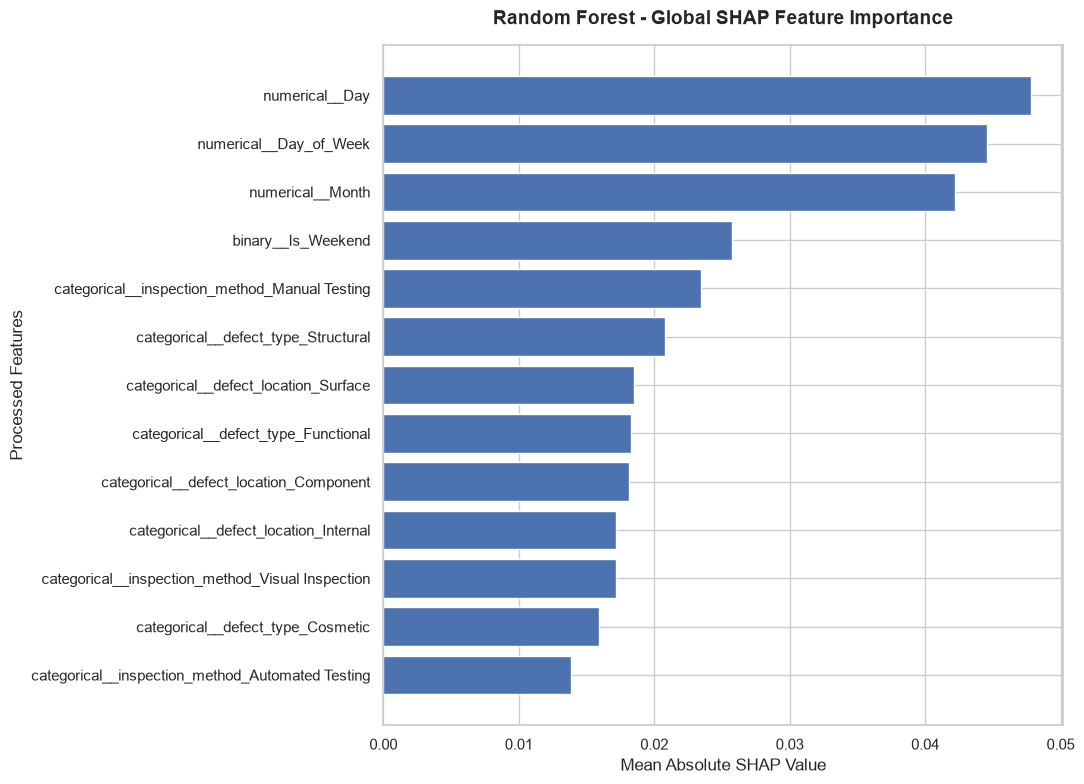

In [22]:
# Visualizing global SHAP feature importance

fig, ax = plt.subplots(figsize=(11, 8))

plot_data = shap_importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

ax.barh(
    plot_data["Feature"],
    plot_data["Mean_Absolute_SHAP"]
)

ax.set_title(
    "Random Forest - Global SHAP Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Mean Absolute SHAP Value")
ax.set_ylabel("Processed Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "random_forest_global_shap_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### 10.5 Investigating Class-Specific SHAP Importance

In [23]:
# Calculating class-specific SHAP feature importance

class_shap_importance = {}

for class_index, class_name in enumerate(label_encoder.classes_):

    class_shap_importance[class_name] = (
        np.abs(shap_values.values[:, :, class_index])
        .mean(axis=0)
    )

# Organizing class-specific SHAP importance

class_shap_importance_df = pd.DataFrame({
    "Feature": X_shap.columns,
    **class_shap_importance
})

# Calculating overall mean importance

class_shap_importance_df["Overall_Importance"] = (
    class_shap_importance_df[
        list(label_encoder.classes_)
    ].mean(axis=1)
)

# Sorting features by overall importance

class_shap_importance_df = (
    class_shap_importance_df
    .sort_values("Overall_Importance", ascending=False)
    .reset_index(drop=True)
)

print("Random Forest - Class-Specific SHAP Feature Importance:")

display(class_shap_importance_df.round(4))

Random Forest - Class-Specific SHAP Feature Importance:


,Feature,Critical,Minor,Moderate,Overall_Importance
0,numerical__Day,0.0485,0.0472,0.0477,0.0478
1,numerical__Day_of_Week,0.0410,0.0496,0.0431,0.0446
2,numerical__Month,0.0416,0.0504,0.0345,0.0422
3,binary__Is_Weekend,0.0273,0.0180,0.0321,0.0258
4,categorical__inspection_method_Manual Testing,0.0205,0.0248,0.0251,0.0235
5,categorical__defect_type_Structural,0.0169,0.0230,0.0225,0.0208
6,categorical__defect_location_Surface,0.0177,0.0196,0.0182,0.0185
7,categorical__defect_type_Functional,0.0176,0.0170,0.0201,0.0183
8,categorical__defect_location_Component,0.0203,0.0160,0.0182,0.0181
9,categorical__defect_location_Internal,0.0171,0.0169,0.0175,0.0172


#### Observations on Class-Specific SHAP Importance

- **Day** showed consistently high importance across all three severity classes, with mean absolute SHAP values ranging from **0.0472 to 0.0485**.
- **Minor defects** showed greater reliance on Month (0.0504) and Day of Week (0.0496), while **Moderate defects** showed the highest Weekend importance (0.0321).
- **Defect Type, Defect Location, and Inspection Method** generally contributed less than temporal features across all three classes.

##### 10.6 Visualizing Class-Specific SHAP Importance

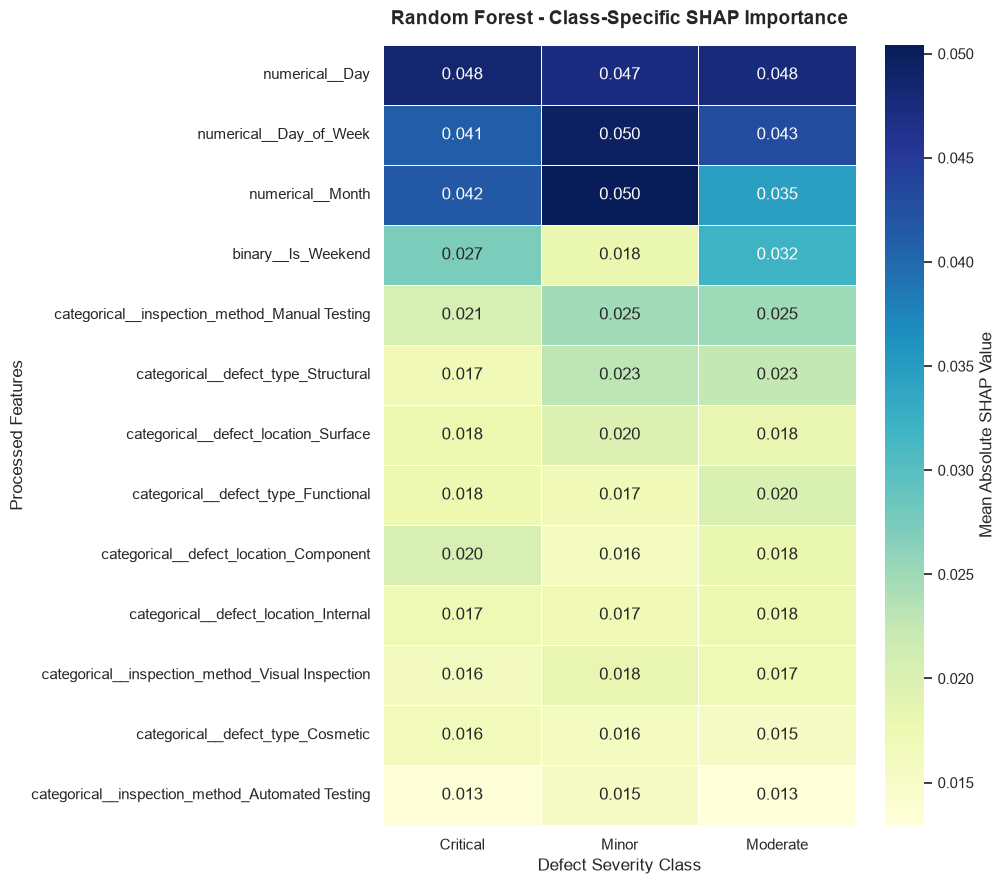

In [24]:
# Preparing class-specific SHAP importance matrix

shap_heatmap_data = (
    class_shap_importance_df
    .set_index("Feature")[
        ["Critical", "Minor", "Moderate"]
    ]
)

# Visualizing class-specific SHAP importance

fig, ax = plt.subplots(figsize=(10, 9))

sns.heatmap(
    shap_heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={
        "label": "Mean Absolute SHAP Value"
    },
    ax=ax
)

ax.set_title(
    "Random Forest - Class-Specific SHAP Importance",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Defect Severity Class")
ax.set_ylabel("Processed Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "random_forest_class_specific_shap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 10.7 Investigating Individual SHAP Explanations

In [25]:
# Identifying a Critical prediction for individual SHAP analysis

shap_predictions = random_forest.predict(X_shap)

critical_class = int(
    label_encoder.transform(["Critical"])[0]
)

critical_indices = np.where(
    shap_predictions == critical_class
)[0]

print("Number of Predicted Critical Defects:", len(critical_indices))

if len(critical_indices) > 0:

    selected_index = int(critical_indices[0])

    selected_observation = X_shap.iloc[[selected_index]]

    predicted_class = label_encoder.inverse_transform(
        [shap_predictions[selected_index]]
    )[0]

    predicted_probability = random_forest.predict_proba(
        selected_observation
    )[0, critical_class]

    print("\nSelected Observation Index:", selected_index)
    print("Predicted Severity:", predicted_class)
    print("Predicted Critical Probability:", round(predicted_probability, 4))

    print("\nSelected Observation Features:")
    display(selected_observation.T)

else:
    print("No Critical predictions found in the SHAP sample.")

Number of Predicted Critical Defects: 28

Selected Observation Index: 3
Predicted Severity: Critical
Predicted Critical Probability: 0.69

Selected Observation Features:


,619
categorical__defect_type_Cosmetic,1.0000
categorical__defect_type_Functional,0.0000
categorical__defect_type_Structural,0.0000
categorical__defect_location_Component,0.0000
categorical__defect_location_Internal,1.0000
categorical__defect_location_Surface,0.0000
categorical__inspection_method_Automated Testing,0.0000
categorical__inspection_method_Manual Testing,1.0000
categorical__inspection_method_Visual Inspection,0.0000
numerical__Month,-0.8281


##### 10.8 Visualizing Individual SHAP Contributions

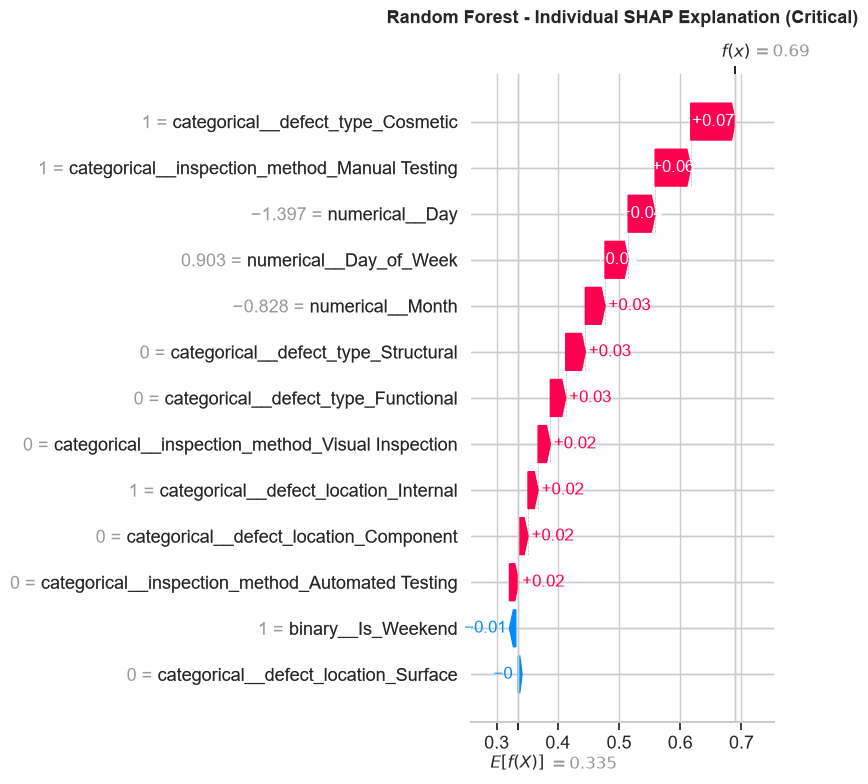

In [26]:
# Extracting SHAP explanation for the Critical class

critical_shap_explanation = shap_values[
    selected_index, :, critical_class
]

# Creating the SHAP waterfall plot

shap.plots.waterfall(
    critical_shap_explanation,
    max_display=13,
    show=False
)

plt.title(
    "Random Forest - Individual SHAP Explanation (Critical)",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    figures_dir / "random_forest_critical_shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

##### 10.9 Comparing Individual SHAP Explanations Across Severity Classes


Predicted Severity: Minor
Predicted Probability: 0.9200


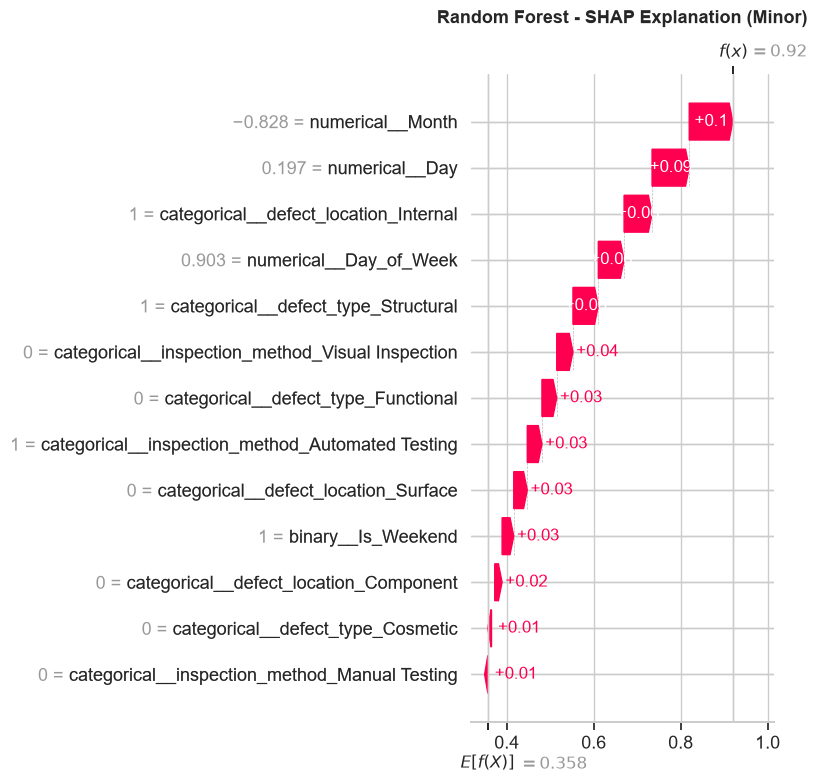


Predicted Severity: Moderate
Predicted Probability: 0.9250


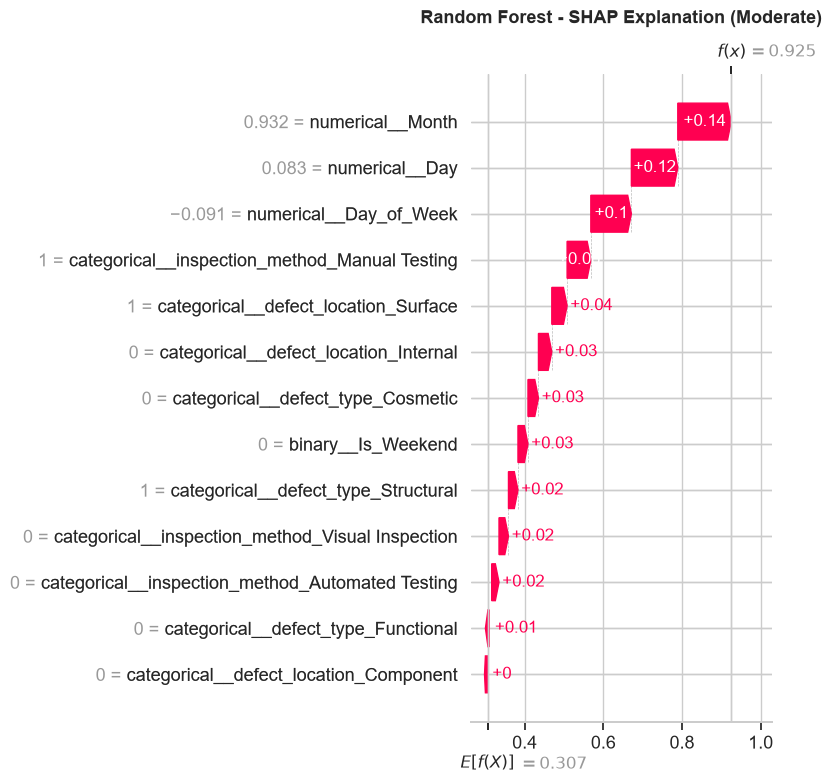

In [27]:
# Visualizing individual SHAP explanations for Minor and Moderate

for class_name in ["Minor", "Moderate"]:

    class_index = int(
        label_encoder.transform([class_name])[0]
    )

    matching_indices = np.where(
        shap_predictions == class_index
    )[0]

    if len(matching_indices) == 0:
        print(f"No predicted {class_name} observations found.")
        continue

    observation_index = int(matching_indices[0])

    # Extracting the class-specific SHAP explanation

    class_explanation = shap_values[
        observation_index, :, class_index
    ]

    # Displaying the predicted class probability

    probability = random_forest.predict_proba(
        X_shap.iloc[[observation_index]]
    )[0, class_index]

    print(f"\nPredicted Severity: {class_name}")
    print(f"Predicted Probability: {probability:.4f}")

    # Creating the waterfall plot

    shap.plots.waterfall(
        class_explanation,
        max_display=13,
        show=False
    )

    plt.title(
        f"Random Forest - SHAP Explanation ({class_name})",
        fontsize=13,
        fontweight="bold",
        pad=15
    )

    plt.tight_layout()

    plt.savefig(
        figures_dir / f"random_forest_{class_name.lower()}_shap_waterfall.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

##### 10.10 Saving SHAP Explainability Results

In [28]:
# Saving global SHAP feature importance

shap_importance_df.to_csv(
    processed_dir / "random_forest_global_shap_importance.csv",
    index=False
)

# Saving class-specific SHAP feature importance

class_shap_importance_df.to_csv(
    processed_dir / "random_forest_class_specific_shap_importance.csv",
    index=False
)

# Verifying saved results

shap_files = [
    "random_forest_global_shap_importance.csv",
    "random_forest_class_specific_shap_importance.csv"
]

for filename in shap_files:
    filepath = processed_dir / filename

    print(
        f"{filename}: "
        f"{'Saved' if filepath.exists() else 'Missing'}"
    )

random_forest_global_shap_importance.csv: Saved
random_forest_class_specific_shap_importance.csv: Saved


### 10.11 Key Findings and Limitations

#### Key Findings

1. **Global Feature Importance:** Day, Day of Week, and Month recorded the highest mean absolute SHAP values, indicating that temporal features had the greatest influence on Random Forest's predicted severity probabilities.

2. **Class-Specific Explanations:** Temporal features remained influential across Critical, Minor, and Moderate predictions, although their relative importance varied between severity classes.

3. **Individual Prediction Explanations:** SHAP waterfall plots illustrated how individual feature contributions increased or decreased predicted class probabilities relative to their baseline values.

4. **Consistency Across Methods:** Global SHAP importance broadly agreed with Random Forest's impurity-based and permutation importance analyses, particularly regarding the importance of temporal features.

#### Limitations

- **Weak Generalization:** Random Forest achieved a training Macro F1-score of 0.9365 but only 0.3236 on the test dataset, indicating substantial overfitting.
- **Training-Based Explanations:** SHAP values were calculated using 100 sampled training observations, limiting conclusions about model behavior on unseen data.
- **Feature Dependencies:** Relationships among temporal features may influence how SHAP distributes contributions between them.
- **Non-Causal Interpretations:** SHAP explains model predictions but does not establish causal relationships between manufacturing characteristics and defect severity.

### 10.12 Conclusion

The SHAP analysis provided additional insight into the Random Forest classifier by examining global feature importance, class-specific contributions, and individual prediction explanations.

The findings highlighted the model's reliance on temporal features, particularly Day, Day of Week, and Month, while demonstrating how feature contributions varied across defect severity classes.

Although SHAP offered more detailed explanations of the model's predictions, the classifier's substantial overfitting and limited test performance restrict the reliability of these interpretations.

Overall, SHAP complemented the existing coefficient-based and permutation importance analyses, providing a more comprehensive understanding of model behavior while reinforcing the importance of predictive reliability.